# Preserving memory with a fixed-width operator

The fixed-width rule stops before the first weight smaller than a chosen cutoff and uses the same retained weights at every valid time:

$$
m_{\tau}(d)=\min\{m\geq1:|\omega_m|<\tau\},\qquad
\widetilde X_t^{(d,\tau)}=\sum_{k=0}^{m_{\tau}(d)-1}\omega_kX_{t-k}.
$$

Here, $d$ is the difference order; $\tau>0$ is the absolute-weight cutoff; $m_{\tau}(d)$ is the first excluded lag. $\omega_k$ is the lag-$k$ weight; $X_{t-k}$ is the level $k$ steps before $t$; $\widetilde X_t^{(d,\tau)}$ is the transformed value.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("08_fractional_differentiation");
using CSV, Printf, HypothesisTests
using RiskLabAI.Data: calculate_weights_std,calculate_weights_ffd,fractional_difference_std,fractional_difference_fixed,adaptive_fractional_difference
raw = load_binance()
data_path = dataset_path("binance_btcusdt")
@assert isfile(data_path)
minute_close = raw.close
resampled = combine(groupby(DataFrame(time=floor.(raw.time,Minute(15)),price=raw.close),:time;sort=true),:price=>last=>:close)
close_index,close_prices = resampled.time,resampled.close
log_price = log.(close_prices)
violet = "#C084FC"

function natural_weights(degree,size)
    values = ones(size)
    for lag in 1:size-1
        values[lag+1] = -values[lag]*(degree-lag+1)/lag
    end
    return values
end

function adf_record(values)
    test = ADFTest(Float64.(values),:constant,1)
    return (statistic=test.stat,p_value=pvalue(test),lag=test.lag,observations=test.n,critical=HypothesisTests.adf_cv(test.n,:constant)[2])
end

function fixed_transform(values,degree,cutoff)
    transformed = fractional_difference_fixed(values,degree;threshold=cutoff)
    positions = findall(isfinite,transformed)
    return (positions=positions,values=transformed[positions])
end

function save_adf_records(records,stem)
    save_data(DataFrame(records),paths,stem)
    return nothing
end


save_adf_records (generic function with 1 method)

## Constant Windows

In [2]:
width_rows,transform_rows,comparison_rows,adf_rows = NamedTuple[],NamedTuple[],NamedTuple[],NamedTuple[]
for threshold in [1e-2,1e-3,1e-4], degree in [.1,.2,.4,.6,.8,1.]
    weights = reverse(calculate_weights_ffd(degree,threshold))
    next_lag = length(weights)
    next_weight = -weights[end]*(degree-next_lag+1)/next_lag
    push!(width_rows,(cutoff=threshold,order=degree,width=length(weights),warmup=length(weights)-1,smallest=minimum(abs.(weights)),excluded=abs(next_weight),sum=sum(weights)))
end
window_width_summary = DataFrame(width_rows)
rename!(window_width_summary,["Cutoff","Order","Retained weights","Warm-up records","Smallest retained absolute weight","First excluded absolute weight","Retained signed sum"])
fixed_outputs = Dict{Float64,Any}()
fixed_output_rows = NamedTuple[]
for degree in [0.,.1,.2,.5,1.]
    transformed = fixed_transform(log_price,degree,1e-3)
    fixed_outputs[degree] = transformed
    record = adf_record(transformed.values)
    push!(adf_rows,merge((order=degree,),record))
    push!(transform_rows,(order=degree,width=length(calculate_weights_ffd(degree,1e-3)),observations=length(transformed.values),mean=mean(transformed.values),sd=std(transformed.values),correlation=cor(log_price[transformed.positions],transformed.values),p_value=record.p_value))
    for (position,value) in zip(transformed.positions,transformed.values)
        push!(fixed_output_rows,(order=degree,position=position,time=close_index[position],value=value))
    end
end
fixed_transform_summary = DataFrame(transform_rows)
rename!(fixed_transform_summary,["Order","Retained weights","Usable observations","Mean","Standard deviation","Correlation with log price","ADF p-value"])
degree = .4
expanding_full = fractional_difference_std(log_price,degree;threshold=.01)
expanding_positions = findall(isfinite,expanding_full)
expanding = (positions=expanding_positions,values=expanding_full[expanding_positions])
fixed = fixed_transform(log_price,degree,1e-3)
comparison_data = NamedTuple[]
for (name,transformed) in [("Expanding window",expanding),("Fixed width",fixed)]
    values,positions = transformed.values,transformed.positions
    elapsed_days = Dates.value.(close_index[positions].-close_index[first(positions)])./86400000
    centered_days = elapsed_days.-mean(elapsed_days)
    slope = dot(centered_days,values.-mean(values))/sum(abs2,centered_days)
    push!(comparison_rows,(method=name,observations=length(values),first_time=close_index[first(positions)],mean=mean(values),sd=std(values),slope=slope,correlation=cor(log_price[positions],values)))
    for (position,value) in zip(positions,values)
        push!(comparison_data,(method=name,position=position,time=close_index[position],value=value))
    end
end
expanding_fixed_summary = DataFrame(comparison_rows)
rename!(expanding_fixed_summary,["Method","Usable observations","First usable time","Mean","Standard deviation","Linear slope per day","Correlation with log price"])
save_table(window_width_summary,paths,"window_width_summary";caption="Fixed-width lengths under three absolute-weight cutoffs.",label="tab:chapter7-window-width")
save_table(fixed_transform_summary,paths,"fixed_transform_summary";caption="Public-data fixed-width results at a cutoff of 0.001.",label="tab:chapter7-fixed-transform")
save_table(expanding_fixed_summary,paths,"expanding_fixed_summary";caption="Expanding-window and fixed-width results for order 0.4.",label="tab:chapter7-expanding-fixed")
save_adf_records(adf_rows,"fixed_transform_adf")
save_data(DataFrame(fixed_output_rows),paths,"fixed_transform_values")
save_data(DataFrame(comparison_data),paths,"expanding_fixed_values");


Row,Cutoff,Order,Retained weights,Warm-up records,Smallest retained absolute weight,First excluded absolute weight,Retained signed sum
,Float64,Float64,Int64,Int64,Float64,Float64,Float64
1,0.01,0.1,8,7,0.0110937,0.00956831,0.765465
2,0.01,0.2,11,10,0.010973,0.00977597,0.537678
3,0.01,0.4,11,10,0.0110064,0.0096056,0.264154
4,0.01,0.6,9,8,0.0103404,0.00850207,0.127531
5,0.01,0.8,6,5,0.011264,0.0078848,0.059136
6,0.01,1.0,2,1,1.0,0.0,0.0
7,0.001,0.1,62,61,0.0010179,0.000999836,0.619898
8,0.001,0.2,73,72,0.00101606,0.000999356,0.364765
9,0.001,0.4,55,54,0.00101396,0.000988154,0.135871


Row,Order,Retained weights,Usable observations,Mean,Standard deviation,Correlation with log price,ADF p-value
,Float64,Int64,Int64,Float64,Float64,Float64,Float64
1,0.0,1,2976,10.4458,0.0849584,1.0,0.0488379
2,0.1,62,2915,6.47762,0.0524015,0.994719,0.00156553
3,0.2,73,2904,3.81201,0.0325714,0.966637,2.95719e-7
4,0.5,44,2933,0.896488,0.0117114,0.691952,2.02974e-29
5,1.0,2,2975,4.72558e-5,0.00779784,0.0381332,0.0


Row,Method,Usable observations,First usable time,Mean,Standard deviation,Linear slope per day,Correlation with log price
,String,Int64,DateTime,Float64,Float64,Float64,Float64
1,Expanding window,768,2021-01-24T00:00:00,0.300575,0.0144305,-0.00356583,0.30277
2,Fixed width,2922,2021-01-01T13:30:00,1.41989,0.0152885,-0.000330787,0.816566


## Truncation Error

If the omitted past levels are bounded, the error from cutting the weight tail is no larger than their bound times the omitted absolute weight:

$$
\left|\sum_{k=m}^{\infty}\omega_kX_{t-k}\right|
\leq M_t\sum_{k=m}^{\infty}|\omega_k|,qquad
M_t=\sup_{k\geq m}|X_{t-k}|.
$$

Here, $m$ is the first omitted lag; $\omega_k$ is the weight at lag $k$; $X_{t-k}$ is the omitted past level. $M_t$ is the largest absolute omitted level at time $t$; $\sup$ denotes the least upper bound; $|\cdot|$ is absolute value.

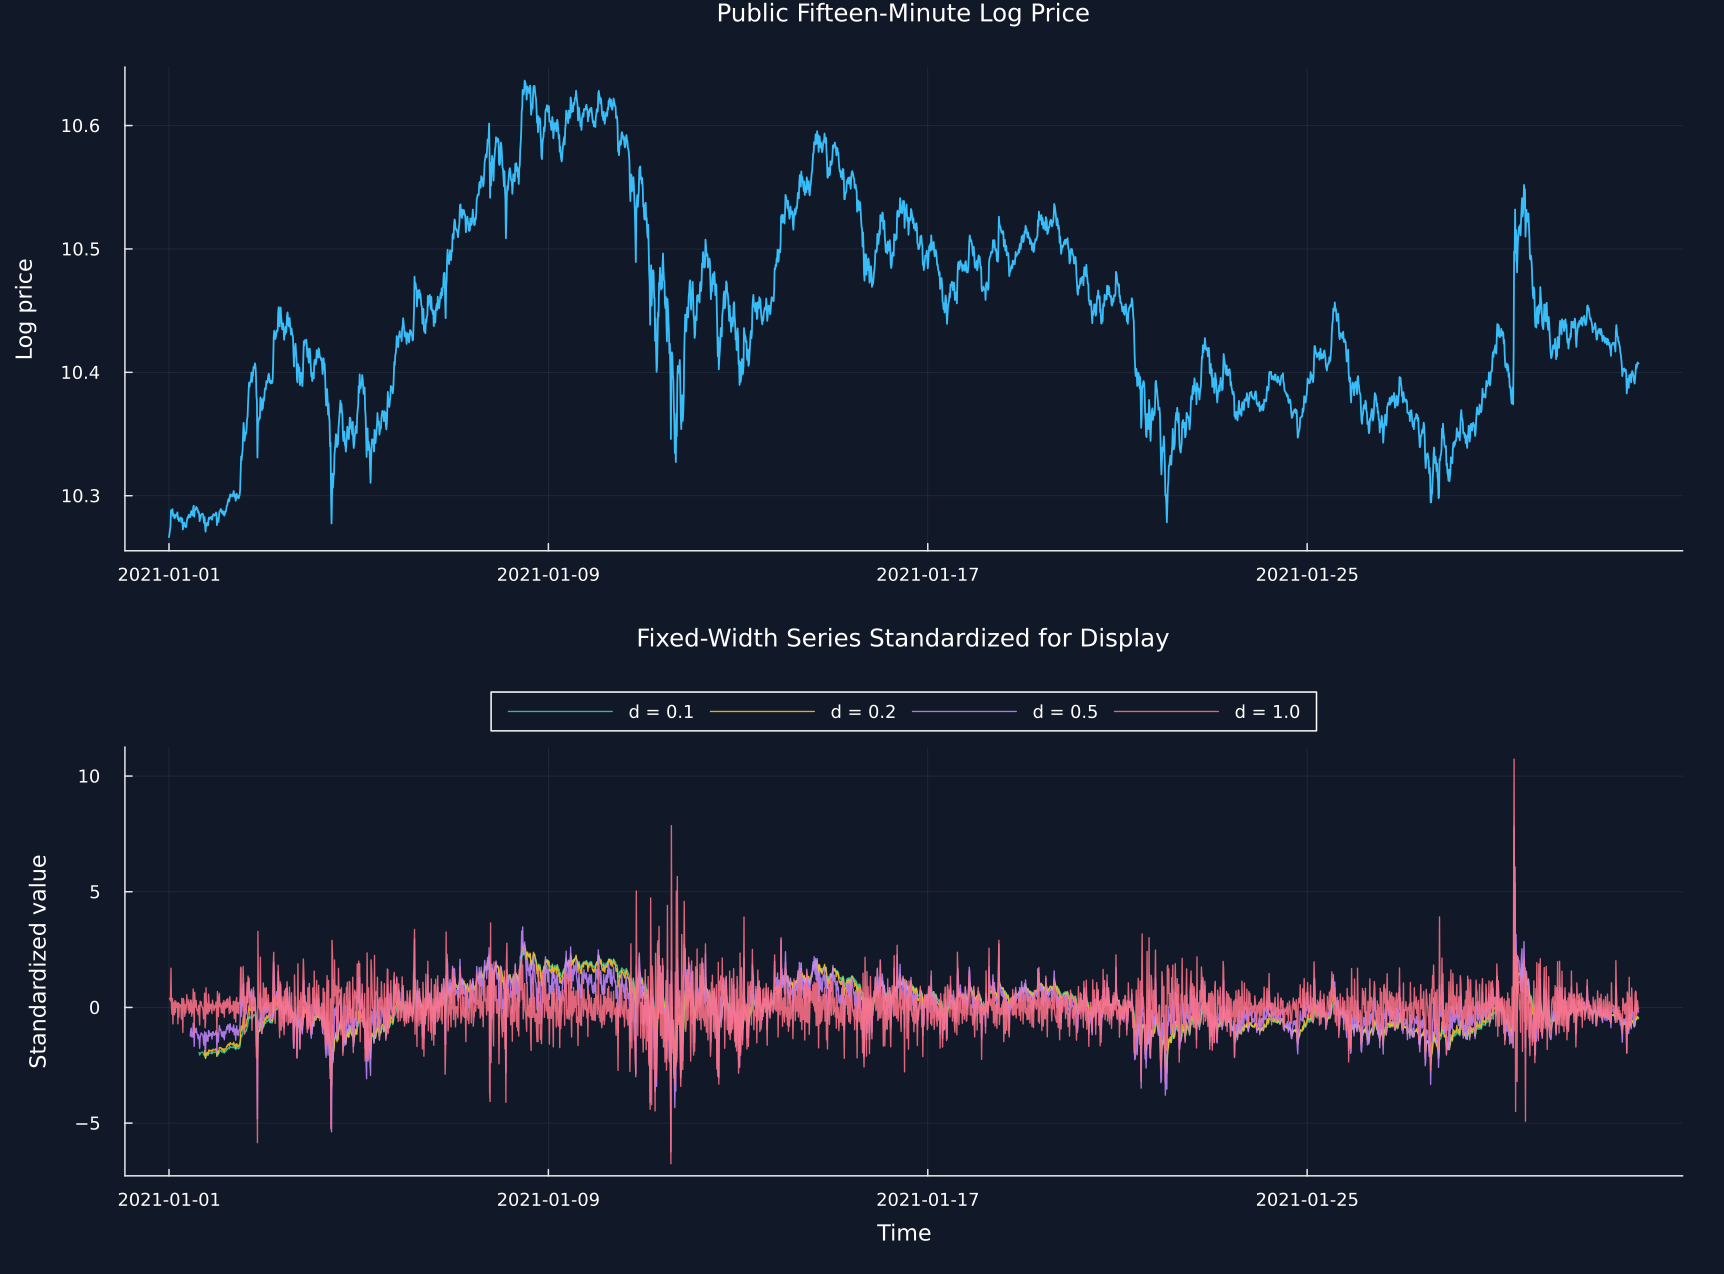

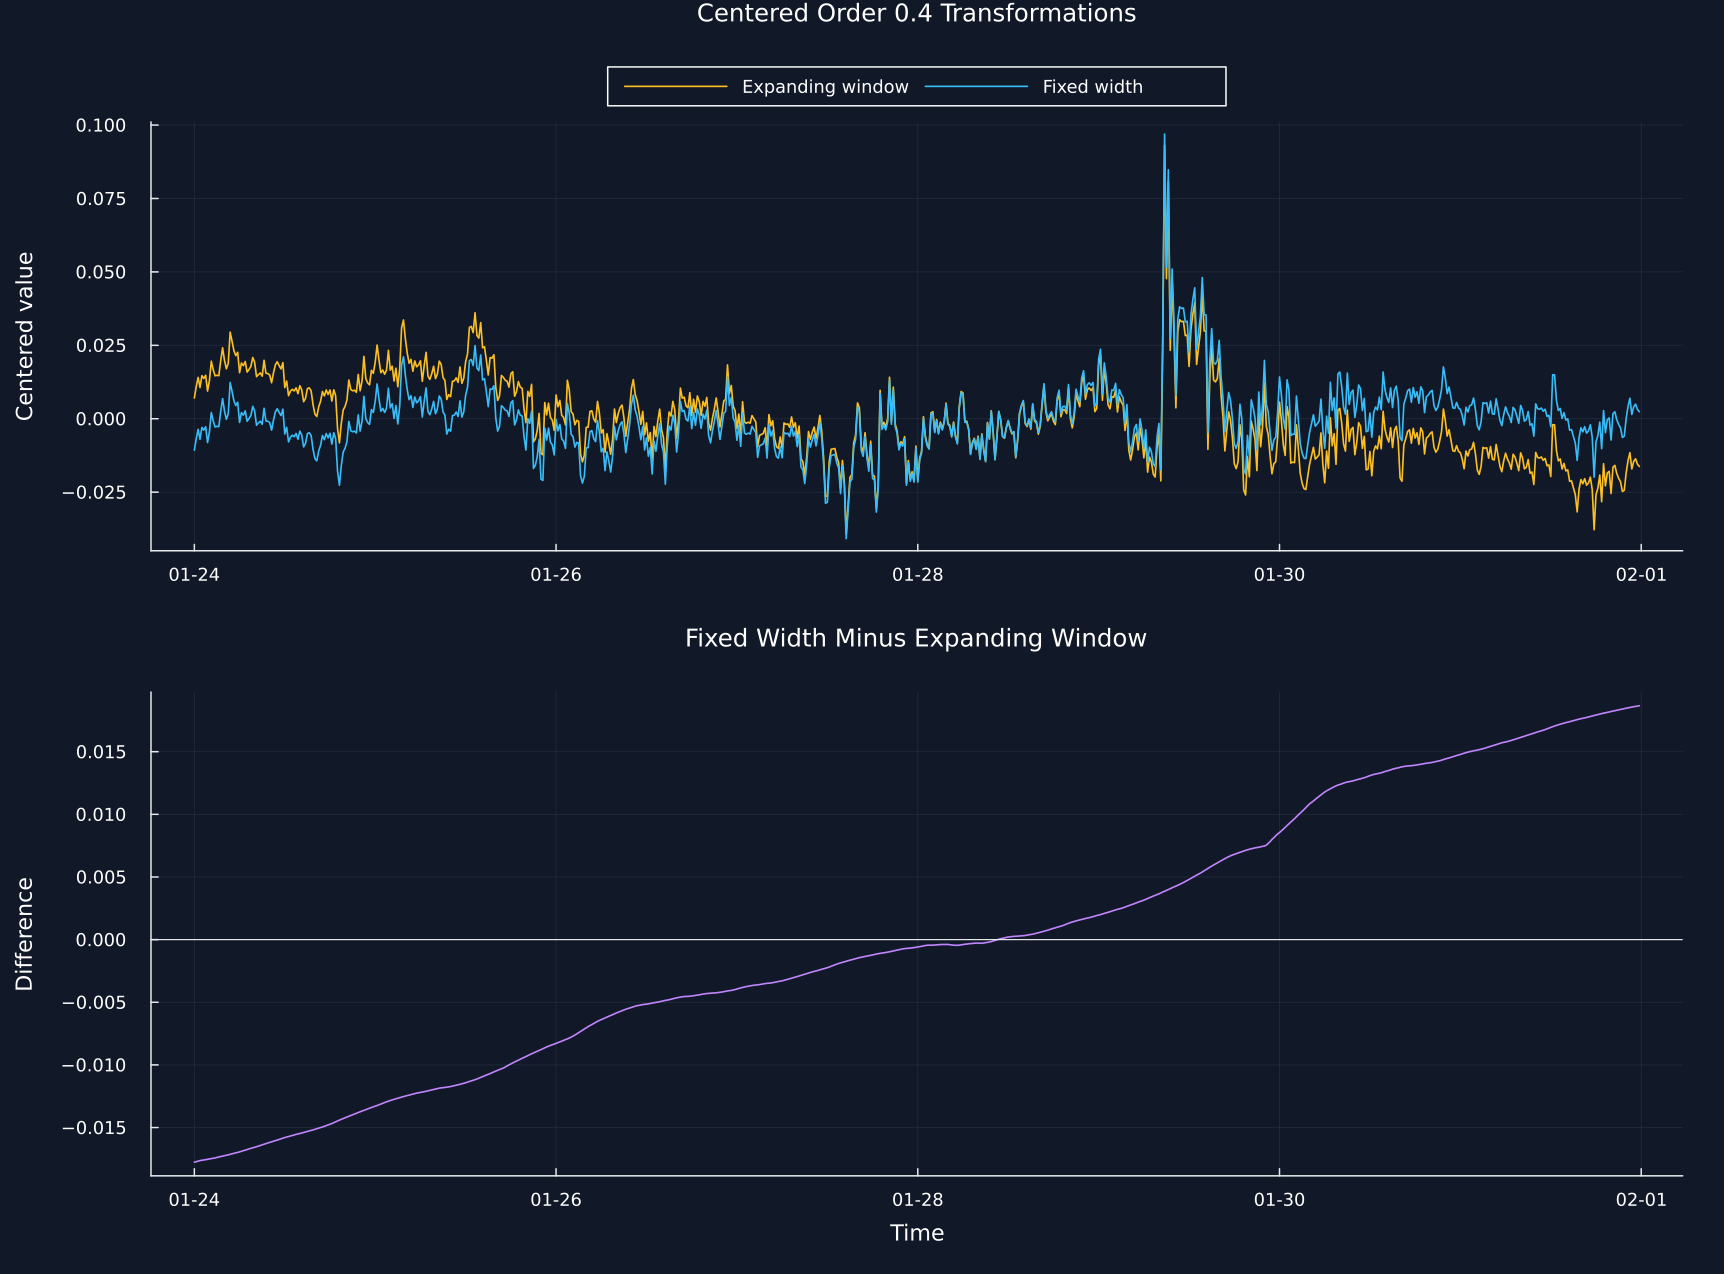

In [3]:
p1 = plot(close_index,log_price;color=palette.cyan,linewidth=1.2,title="Public Fifteen-Minute Log Price",ylabel="Log price",legend=false)
p2 = plot(;title="Fixed-Width Series Standardized for Display",xlabel="Time",ylabel="Standardized value",legend=:outertop,legend_column=4)
for (degree,color) in [(.1,palette.green),(.2,palette.amber),(.5,violet),(1.,palette.rose)]
    transformed = fixed_outputs[degree]
    standardized = (transformed.values.-mean(transformed.values))./std(transformed.values)
    plot!(p2,close_index[transformed.positions],standardized;color,linewidth=.9,alpha=.88,label="d = $degree")
end
save_figure(plot(p1,p2;layout=(2,1),link=:x,size=(1150,850)),paths,"fixed_width_transforms")
common_positions = intersect(expanding.positions,fixed.positions)
expanding_centered = expanding_full[common_positions].-mean(expanding_full[common_positions])
fixed_full = fractional_difference_fixed(log_price,.4;threshold=1e-3)
fixed_centered = fixed_full[common_positions].-mean(fixed_full[common_positions])
difference = fixed_centered.-expanding_centered
p1 = plot(close_index[common_positions],expanding_centered;color=palette.amber,linewidth=1.1,label="Expanding window",title="Centered Order 0.4 Transformations",ylabel="Centered value",legend=:outertop,legend_column=2)
plot!(p1,close_index[common_positions],fixed_centered;color=palette.cyan,linewidth=1.1,label="Fixed width")
p2 = plot(close_index[common_positions],difference;color=violet,linewidth=1.1,title="Fixed Width Minus Expanding Window",xlabel="Time",ylabel="Difference",legend=false)
hline!(p2,[0.];color=palette.text,linewidth=.8,label=false)
time_ticks = collect(DateTime(2021,1,24):Day(2):DateTime(2021,2,1))
save_figure(plot(p1,p2;layout=(2,1),link=:x,xticks=(Dates.value.(time_ticks),Dates.format.(time_ticks,dateformat"mm-dd")),size=(1150,850)),paths,"expanding_fixed_comparison")
save_data(DataFrame(position=common_positions,time=close_index[common_positions],expanding_centered=expanding_centered,fixed_centered=fixed_centered,difference=difference),paths,"centered_comparison");


## Memory Retention

Correlation with the aligned original level is used as a simple sample measure of retained linear memory:

$$
M(d,\tau)=\operatorname{Corr}\!\left(X_t,\widetilde X_t^{(d,\tau)}\right),
\qquad -1\leq M(d,\tau)\leq1.
$$

Here, $M(d,\tau)$ is the sample memory measure; $d$ is the difference order; $\tau$ is the weight cutoff. $X_t$ is the original level; $\widetilde X_t^{(d,\tau)}$ is the aligned fixed-width value; $\operatorname{Corr}$ is sample correlation.

## Tests

In [4]:
degree,threshold = .4,1e-3
weights = reverse(calculate_weights_ffd(degree,threshold))
manual = [dot(weights,reverse(log_price[position-length(weights)+1:position])) for position in length(weights):length(log_price)]
released = fixed_transform(log_price,degree,threshold)
next_lag = length(weights)
next_weight = -weights[end]*(degree-next_lag+1)/next_lag
identity = fixed_transform(log_price,0.,threshold)
first_difference = fixed_transform(log_price,1.,threshold)
shifted = fixed_transform(log_price.+2.,degree,threshold)
causal_prefix = fixed_transform(log_price[1:end-1],degree,threshold)
@assert nrow(window_width_summary)==18
@assert all(window_width_summary[!,"Smallest retained absolute weight"].>=window_width_summary.Cutoff)
@assert all(window_width_summary[!,"First excluded absolute weight"].<window_width_summary.Cutoff)
@assert isapprox(manual,released.values)
@assert first(released.positions)==length(weights)
@assert length(released.values)==length(log_price)-length(weights)+1
@assert isapprox(identity.values,log_price)
@assert isapprox(first_difference.values,diff(log_price))
@assert all(isapprox.(shifted.values.-released.values,2sum(weights)))
@assert isapprox(causal_prefix.values,released.values[1:end-1])
@assert all(-1 .<=fixed_transform_summary[!,"Correlation with log price"].<=1)
@assert only(fixed_transform_summary[fixed_transform_summary.Order.==1.,"Correlation with log price"])<.1
@assert only(fixed_transform_summary[fixed_transform_summary.Order.==.1,"Correlation with log price"])>.98
@assert nrow(expanding_fixed_summary)==2
@assert all(isfinite,Matrix(expanding_fixed_summary[:,[2,4,5,6,7]]))
@assert isfile(joinpath(paths.figures,"fixed_width_transforms.pdf"))
@assert isfile(joinpath(paths.figures,"expanding_fixed_comparison.pdf"))
save_data(DataFrame(position=released.positions,manual=manual,released=released.values,shifted=shifted.values),paths,"fixed_filter_contracts");
